# Molecular Docking + MD — Ebola VP40: 4LDB library screening

Real multi-compound screening question: screen real, LARGE PubChem-similarity-expanded libraries (target
1000+ compounds per class) across 3 mechanistic classes (triterpenoids/betulinic-acid derivatives,
microtubule/cytoskeletal disruptors, allosteric oligomerisation-disrupting "wedges" built around the
SERM-class seed) against 4LDB (Ebola VP40 matrix protein dimer), using a real multi-stage funnel: (1)
bulk 2D-property fetch + a drug-likeness/ADMET filter (Lipinski + Veber) on the WHOLE library, zero
docking compute spent, (2) ligand-based similarity to a real documented VP40 binder (salicylic acid),
also on the whole library, (3) combine both to pick a real top-15 docking shortlist, (4) only THEN build
real 3D, protonated structures for those 15, (5) a fast coarse Vina pass on the 15, (6) exhaustive,
high-settings Vina redocking on just the top 3 survivors -- then run MD on ONLY the single most promising
compound that survives every stage (PROJECT_NARRATIVE.md Section 5/6), the way real drug-discovery triage
narrows a huge library down before committing to the expensive physics-based stage.

Per your own instruction earlier in this project, this notebook is fully written (no `____` blanks to
fill in) so it can be run straight through on Kaggle. GROMACS is installed via a real, verified-to-exist
prebuilt CUDA binary from conda-forge (`mamba install -c conda-forge -c bioconda "gromacs=*=*cuda*"`),
which is faster and more network-reliable on Kaggle than compiling GROMACS from source.


In [1]:
import os

# directories only -- every package below is installed right before the cell that first needs it,
# not all up front. This way if Kaggle gives you a fresh kernel partway through, you only need to
# re-run the installs for the step you're actually on, not guess which one silently vanished.
for d in ["data/receptors", "data/ligands", "data/pockets", "results/docking"]:
    os.makedirs(d, exist_ok=True)
print("directories ready")


directories ready


## Step 0 — Directories only

Packages are installed just-in-time, immediately before the cell that first needs them (Step 2:
`openbabel-wheel`; Step 3: `fpocket`; Step 4: `rdkit`/`meeko`/`gemmi`; Step 5: `vina`; Step 6:
`gromacs`/`pdbfixer`/`openmm`/`acpype`; the visualization step: `py3Dmol`) -- so a fresh Kaggle
kernel only ever costs you a re-install of what the step you're actually on needs, not a guess about
what silently disappeared from a giant Step 0.

## Step 1 — Fetch the real receptor structure (4LDB)

**WHAT:** download the real PDB coordinate file for this target, live from RCSB.
**WHY (biology):** Ebola VP40. This is a real, experimentally-solved X-ray structure (see
`PROJECT_NARRATIVE.md` Section 3a for how it was actually generated).
**HOW:** RCSB's file-download endpoint follows a fixed real pattern:
`https://files.rcsb.org/download/{PDB_ID}.pdb` — look up `requests.get` + `.text`, write to
`data/receptors/4LDB.pdb`.

In [2]:
import requests

PDB_ID = "4LDB"

url = f"https://files.rcsb.org/download/{PDB_ID}.pdb"
resp = requests.get(url)
with open(f"data/receptors/{PDB_ID}.pdb", "w") as f:
    f.write(resp.text)
print(PDB_ID, "saved,", len(resp.text), "chars")


4LDB saved, 683073 chars


## Step 2 — Prepare the receptor (strip waters, resolve alternate conformations, add hydrogens)

**WHAT:** clean the raw crystal PDB into a docking-ready, geometrically well-behaved receptor.
**WHY (biology):** crystallographic waters and buffer/cryoprotectant molecules are real experimental
artifacts of crystallization, not part of the biological binding event, and must be removed. Separately,
many real X-ray structures (6ML0 included — confirmed live: it has 26 real altLoc-B atoms) resolve some
sidechains into two real **alternate conformations** ("altLoc" A/B records at near-identical coordinates,
representing genuine crystallographic ambiguity about which rotamer is "真" at that position). Downstream
tools that build 3D geometry from the atom set (fpocket's internal Voronoi/qhull step, in particular) can
crash on these near-duplicate points if both conformations are kept — so real structural-biology practice is
to keep only ONE conformation (conventionally altLoc "A", or blank where there's no alternate) before any
geometric computation.
**WHY (chemistry):** hydrogens are usually invisible at X-ray resolution and must be added back
computationally, at a real, chosen protonation state (physiological pH ~7.4).
**HOW:** filter by residue name AND by the real PDB altLoc column (column 17, 0-indexed `line[16]`), then
Open Babel: `obabel input.pdb -O output.pdbqt -xr --partialcharge gasteiger` (`-xr` = rigid receptor
output).

In [3]:
import sys
!{sys.executable} -m pip install -q openbabel-wheel

WATER_BUFFER_RESNAMES = {"HOH", "GOL", "PEG", "EDO", "SO4", "PO4", "MES", "ACT", "NA", "CL", "DMS"}
# GIVEN -- real, standard crystallographic water/buffer/cryoprotectant residue codes (not exhaustive, but
# covers the common ones).

raw_path = f"data/receptors/{PDB_ID}.pdb"
clean_path = f"data/receptors/{PDB_ID}_clean.pdb"
receptor_pdbqt = f"data/receptors/{PDB_ID}_receptor.pdbqt"

with open(raw_path) as f:
    lines = f.readlines()
kept = []
for ln in lines:
    if ln.startswith(("ATOM", "HETATM")):
        if ln[16] not in (" ", "A"):
            continue
        if ln.startswith("HETATM") and ln[17:20].strip() in WATER_BUFFER_RESNAMES:
            continue
    kept.append(ln)
with open(clean_path, "w") as f:
    f.writelines(kept)

!obabel {clean_path} -O {receptor_pdbqt} -xr --partialcharge gasteiger

print("receptor prepared")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 81.5 MB/s eta 0:00:00:00:010:01
*** Open Babel Warning  in PerceiveBondOrders
  Failed to kekulize aromatic bonds in OBMol::PerceiveBondOrders (title is data/receptors/4LDB_clean.pdb)

1 molecule converted
receptor prepared


## Step 3 — Detect the real binding site (fpocket) — NOT blind docking

**WHAT:** run fpocket on the prepared (altLoc-resolved, water-stripped) receptor and choose the real pocket
to dock into.
**WHY (biology):** a binding pocket is a real, druggable cavity — fpocket finds clusters of geometric probe
spheres (alpha-spheres) fitting concave surface regions, ranked by a druggability score. Here, this target has a real co-crystallized ligand in the original PDB file, so you can directly check whether the top-ranked pocket's centroid overlaps the real known ligand position — a real validation of the pocket-detection step itself.
**HOW:** `!fpocket -f data/receptors/{PDB_ID}_clean.pdb` writes a `*_out/` directory with ranked pocket PDB
files (named `pocket1_atm.pdb`, `pocket2_atm.pdb`, ... by druggability rank); parse the chosen pocket's
atoms, compute centroid + a padded bounding box for the Vina search box.
**If fpocket errors with a `qhull`/`QH60xx` message:** that's a real sign Step 2's altLoc filtering didn't
fully resolve a degenerate geometry — re-check `clean_path` for any remaining duplicate-position atoms
before re-running, rather than retrying blindly.

In [4]:
import os, numpy as np, glob

# fpocket: bioconda prebuilt binary, NOT compiled from source (a from-source build was confirmed
# miscompiled in this environment on notebook 01 -- its crash survived 3 independent data-side fixes,
# which is what proved it was a build problem, not a data problem)
if not os.path.exists("/usr/local/miniforge3/bin/mamba"):
    print("installing miniforge...")
    !wget -q https://github.com/conda-forge/miniforge/releases/latest/download/Miniforge3-Linux-x86_64.sh -O /tmp/miniforge.sh
    !bash /tmp/miniforge.sh -b -p /usr/local/miniforge3
    print("miniforge done")

os.environ["PATH"] = "/usr/local/miniforge3/bin:" + os.environ["PATH"]

print("installing fpocket (bioconda) -- real-time output below, takes a few minutes, let it run...")
!mamba install -y -c bioconda -c conda-forge fpocket
!fpocket -h | head -3

!fpocket -f data/receptors/{PDB_ID}_clean.pdb

pocket_files = sorted(glob.glob(f"data/receptors/{PDB_ID}_clean_out/pockets/pocket*_atm.pdb"))
top_pocket_path = pocket_files[0]

coords = []
with open(top_pocket_path) as f:
    for line in f:
        if line.startswith(("ATOM", "HETATM")):
            coords.append([float(line[30:38]), float(line[38:46]), float(line[46:54])])
coords = np.array(coords)

center = coords.mean(axis=0)
box_min, box_max = coords.min(axis=0), coords.max(axis=0)
padding = 5.0
size = (box_max - box_min) + 2 * padding

print("pocket center:", center, "size:", size)


installing miniforge...
PREFIX=/usr/local/miniforge3
Unpacking bootstrapper...
Unpacking payload...
Extracting ca-certificates-2026.7.22-hbd8a1cb_0.conda
Extracting libgomp-16.2.0-he0feb66_4.conda
Extracting libzlib-1.3.2-h25fd6f3_3.conda
Extracting nlohmann_json-abi-3.12.0-h0f90c79_2.conda
Extracting pybind11-abi-11-hc364b38_1.conda
Extracting python_abi-3.14-9_cp314.conda
Extracting tzdata-2026c-h151e31d_0.conda
Extracting _openmp_mutex-4.5-20_gnu.conda
Extracting zstd-1.5.7-hb78ec9c_7.conda
Extracting ld_impl_linux-64-2.46.1-default_hbd61a6d_102.conda
Extracting libgcc-16.2.0-ha9f2e26_4.conda
Extracting bzip2-1.0.8-hda65f42_10.conda
Extracting c-ares-1.34.8-hebe6cf0_2.conda
Extracting keyutils-1.6.3-h7cc23a3_1.conda
Extracting libev-4.33-h280c20c_3.conda
Extracting libexpat-2.8.1-hecca717_1.conda
Extracting libffi-3.7.0-h81df57d_1.conda
Extracting libiconv-1.18-h0cb94f2_3.conda
Extracting liblzma-5.8.3-hb03c661_1.conda
Extracting libmpdec-4.0.0-hb03c661_2.conda
Extracting libstdcxx-

## Step 4 — Fetch REAL, LARGE per-class compound libraries (1000+ per class target)

**WHAT:** for each of the 3 drug classes, use PubChem's 2D similarity search (`fastsimilarity_2d`)
anchored on that class's documented representative (betulinic acid / colchicine / toremifene), at a
relaxed Tanimoto threshold (70%) and a high `MaxRecords` cap, aiming for 1000+ real compounds per class.
**WHY:** a real large-scale screen, not a small hand-picked set -- PubChem's own similarity index is the
real, live, verifiable source for this, not an invented list.
**HOW:** this step ONLY collects CIDs (+ which class each belongs to) -- no 3D structures are fetched yet.
Fetching a real 3D SDF + protonating + writing a PDBQT for several thousand compounds would take far too
long for one Kaggle session and is also pointless: Steps 4a/4b/4c below narrow this down to ~15 compounds
using only cheap, 2D, no-docking computation first. Real 3D structures only get built in Step 4d, for the
~15 survivors. The real count returned per class is printed honestly below -- PubChem may return fewer
than 1000 for a given seed at this threshold, which is itself real information, not something to force.


In [5]:
import time
import requests

# Real, documented representative compounds for each class (verified live against PubChem, not invented)
# -- used as SEEDS for a live, large-scale PubChem 2D-similarity expansion.
SEED_CIDS = {
    64971: "triterpenoid/betulinic-acid class",
    6167: "microtubule/cytoskeletal disruptor class",
    3005573: "SERM-class candidate modulator class",
}

SIMILARITY_THRESHOLD = 70   # Tanimoto %, relaxed from 85% specifically to reach a 1000+ target per class
MAX_PER_CLASS = 1500

LIBRARY_CLASS_LABELS = {}
for seed_cid, class_name in SEED_CIDS.items():
    time.sleep(1)  # politely respect PubChem's real rate limit
    url = (f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/fastsimilarity_2d/cid/{seed_cid}/cids/JSON"
           f"?Threshold={SIMILARITY_THRESHOLD}&MaxRecords={MAX_PER_CLASS}")
    resp = requests.get(url)
    if resp.status_code == 200:
        similar_cids = resp.json().get("IdentifierList", {}).get("CID", [])
    else:
        print(f"WARNING: similarity search failed for seed {seed_cid} (status {resp.status_code}) -- "
              f"falling back to just the seed compound for this class")
        similar_cids = []

    class_cids = sorted(set(similar_cids) | {seed_cid})  # always keep the real documented seed itself
    for cid in class_cids:
        if cid not in LIBRARY_CLASS_LABELS:   # first class to claim a compound wins -- real, disclosed
            LIBRARY_CLASS_LABELS[cid] = class_name
    print(f"seed {seed_cid} ({class_name}): {len(class_cids)} real compounds >= {SIMILARITY_THRESHOLD}% similar")

LIBRARY_CIDS = sorted(LIBRARY_CLASS_LABELS.keys())
print(f"\nTotal real library across all 3 classes: {len(LIBRARY_CIDS)} distinct PubChem CIDs "
      f"(no 3D structures fetched yet -- see Step 4 markdown above for why)")


seed 64971 (triterpenoid/betulinic-acid class): 1500 real compounds >= 70% similar
seed 6167 (microtubule/cytoskeletal disruptor class): 1500 real compounds >= 70% similar
seed 3005573 (SERM-class candidate modulator class): 1500 real compounds >= 70% similar

Total real library across all 3 classes: 4477 distinct PubChem CIDs (no 3D structures fetched yet -- see Step 4 markdown above for why)


## Step 4a-pre — Bulk-fetch 2D properties for the WHOLE library (no per-compound network cost)

**WHAT:** fetch `CanonicalSMILES`, `MolecularWeight`, `XLogP`, `HBondDonorCount`, `HBondAcceptorCount`,
`RotatableBondCount`, `TPSA` for every CID in the library in ONE batched call per ~100 CIDs (PubChem's
batch `property` endpoint accepts a comma-separated CID list), instead of one request per compound.
**WHY:** this is the real reason a 1000+-compound screen is practical in one Kaggle session at all --
fetching a real 3D SDF individually for thousands of compounds (one request each, rate-limited) would take
hours; batched 2D properties for the same thousands of compounds takes under a minute, and 2D properties
are all ADMET filtering (Step 4a) and fingerprint similarity (Step 4b) actually need.
**HOW:** `/compound/cid/{cid1,cid2,...}/property/<names>/JSON`, chunked at 100 CIDs per request, with a
short polite delay between chunks.


In [6]:
import pandas as pd

PROPERTIES = "ConnectivitySMILES,MolecularWeight,XLogP,HBondDonorCount,HBondAcceptorCount,RotatableBondCount,TPSA"
CHUNK_SIZE = 100

property_rows = []
for i in range(0, len(LIBRARY_CIDS), CHUNK_SIZE):
    chunk = LIBRARY_CIDS[i:i + CHUNK_SIZE]
    cid_list = ",".join(str(c) for c in chunk)
    url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{cid_list}/property/{PROPERTIES}/JSON"
    resp = requests.get(url)
    time.sleep(0.3)
    if resp.status_code != 200:
        print(f"WARNING: property batch {i}-{i+len(chunk)} failed (status {resp.status_code}), skipping")
        continue
    props = resp.json().get("PropertyTable", {}).get("Properties", [])
    property_rows.extend(props)
    print(f"fetched properties for {len(props)} compounds (running total: {len(property_rows)} / {len(LIBRARY_CIDS)})")

properties_df = pd.DataFrame(property_rows).rename(columns={"CID": "cid"})
properties_df["class_label"] = properties_df["cid"].map(LIBRARY_CLASS_LABELS)

numeric_cols = ["MolecularWeight", "XLogP", "HBondDonorCount", "HBondAcceptorCount",
                "RotatableBondCount", "TPSA"]
for col in numeric_cols:
    properties_df[col] = pd.to_numeric(properties_df[col], errors="coerce")

before = len(properties_df)
properties_df = properties_df.dropna(subset=numeric_cols)
dropped = before - len(properties_df)
if dropped:
    print(f"Dropped {dropped} compounds with missing/malformed numeric properties (real, disclosed data gap).")

properties_df.to_csv("results/4LDB_library_properties.csv", index=False)
print(f"\nReal 2D properties in hand for {len(properties_df)} of {len(LIBRARY_CIDS)} library compounds.")

fetched properties for 100 compounds (running total: 100 / 4477)
fetched properties for 100 compounds (running total: 200 / 4477)
fetched properties for 100 compounds (running total: 300 / 4477)
fetched properties for 100 compounds (running total: 400 / 4477)
fetched properties for 100 compounds (running total: 500 / 4477)
fetched properties for 100 compounds (running total: 600 / 4477)
fetched properties for 100 compounds (running total: 700 / 4477)
fetched properties for 100 compounds (running total: 800 / 4477)
fetched properties for 100 compounds (running total: 900 / 4477)
fetched properties for 100 compounds (running total: 1000 / 4477)
fetched properties for 100 compounds (running total: 1100 / 4477)
fetched properties for 100 compounds (running total: 1200 / 4477)
fetched properties for 100 compounds (running total: 1300 / 4477)
fetched properties for 100 compounds (running total: 1400 / 4477)
fetched properties for 100 compounds (running total: 1500 / 4477)
fetched properties 

In [7]:
print("Actual columns in your dataframe:", properties_df.columns.tolist())


Actual columns in your dataframe: ['cid', 'MolecularWeight', 'ConnectivitySMILES', 'XLogP', 'TPSA', 'HBondDonorCount', 'HBondAcceptorCount', 'RotatableBondCount', 'class_label']


## Step 4a — Drug-likeness / ADMET pre-filter (on the whole library, zero docking compute spent)

**WHAT:** apply Lipinski's Rule of Five + Veber's rules directly on the batch-fetched 2D properties (no
docking, no 3D structures needed) and drop any candidate that fails them.
**WHY:** this is the first real narrowing of the library -- cheap, instant, and it means later docking
compute is never spent on a candidate that's already a poor drug candidate on paper.
**HOW:** `MW<=500`, `LogP<=5`, `HBD<=5`, `HBA<=10` (<=1 Lipinski violation tolerated, standard practice),
plus Veber (`rotatable_bonds<=10` and `TPSA<=140`). QED (a continuous 0-1 drug-likeness score) is computed
locally from each compound's own `CanonicalSMILES` via RDKit -- no extra network calls needed.


In [8]:
import sys
!{sys.executable} -m pip install -q rdkit

from rdkit import Chem
from rdkit.Chem import QED

admet_rows = []
for _, row in properties_df.iterrows():
    mol = Chem.MolFromSmiles(row["ConnectivitySMILES"])
    if mol is None:
        continue
    qed_score = QED.qed(mol)

    mw, logp = row["MolecularWeight"], row["XLogP"]
    hbd, hba = row["HBondDonorCount"], row["HBondAcceptorCount"]
    rot_bonds, tpsa = row["RotatableBondCount"], row["TPSA"]

    lipinski_violations = sum([mw > 500, logp > 5, hbd > 5, hba > 10])
    veber_pass = (rot_bonds <= 10) and (tpsa <= 140)
    passes_filter = (lipinski_violations <= 1) and veber_pass

    admet_rows.append({
        "cid": row["cid"], "class_label": row["class_label"],
        "MW": mw, "LogP": logp, "HBD": hbd, "HBA": hba,
        "rotatable_bonds": rot_bonds, "TPSA": tpsa, "QED": round(qed_score, 3),
        "lipinski_violations": lipinski_violations, "veber_pass": veber_pass,
        "passes_filter": passes_filter,
    })

admet_df = pd.DataFrame(admet_rows)
admet_df.to_csv("results/4LDB_admet_filter.csv", index=False)
print(f"{admet_df['passes_filter'].sum()} of {len(admet_df)} real library compounds pass the "
      f"drug-likeness pre-filter.")
print(admet_df["passes_filter"].value_counts())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 28.0 MB/s eta 0:00:0000:0100:01
2911 of 3273 real library compounds pass the drug-likeness pre-filter.
passes_filter
True     2911
False     362
Name: count, dtype: int64


## Step 4b — Ligand-based similarity screening against a real documented VP40 binder

**WHAT:** compute 2D Morgan fingerprint Tanimoto similarity between EVERY library compound and salicylic
acid (PubChem CID 338) -- a real, documented VP40 binder (2023 Marburg crystallographic fragment-screening
study, bound at VP40's N-terminal/C-terminal domain interface pocket).
**WHY:** a second, independent "probable binder" signal, orthogonal to docking and to ADMET -- do these
molecules chemically resemble something already proven to bind here.
**HOW:** fingerprints computed directly from each compound's own `CanonicalSMILES` (already in hand from
Step 4a-pre, no extra network calls) vs. salicylic acid's own real SMILES.


In [9]:
from rdkit.Chem import AllChem, DataStructs

REFERENCE_SMILES = "C1=CC=C(C(=C1)C(=O)O)O"  # salicylic acid, PubChem CID 338, verified live
reference_mol = Chem.MolFromSmiles(REFERENCE_SMILES)
reference_fp = AllChem.GetMorganFingerprintAsBitVect(reference_mol, radius=2, nBits=2048)

similarity_rows = []
for _, row in properties_df.iterrows():
    mol = Chem.MolFromSmiles(row["ConnectivitySMILES"])
    if mol is None:
        continue
    fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048)
    tanimoto = DataStructs.TanimotoSimilarity(reference_fp, fp)
    similarity_rows.append({"cid": row["cid"], "class_label": row["class_label"],
                             "tanimoto_to_salicylic_acid": tanimoto})

similarity_df = pd.DataFrame(similarity_rows).sort_values("tanimoto_to_salicylic_acid", ascending=False)
similarity_df.to_csv("results/4LDB_similarity_screen.csv", index=False)
similarity_df.head(10)

[14:02:45] DEPRECATION WARNING: please use MorganGenerator
[14:02:45] DEPRECATION WARNING: please use MorganGenerator
[14:02:45] DEPRECATION WARNING: please use MorganGenerator
[14:02:45] DEPRECATION WARNING: please use MorganGenerator
[14:02:45] DEPRECATION WARNING: please use MorganGenerator
[14:02:45] DEPRECATION WARNING: please use MorganGenerator
[14:02:45] DEPRECATION WARNING: please use MorganGenerator
[14:02:45] DEPRECATION WARNING: please use MorganGenerator
[14:02:45] DEPRECATION WARNING: please use MorganGenerator
[14:02:45] DEPRECATION WARNING: please use MorganGenerator
[14:02:45] DEPRECATION WARNING: please use MorganGenerator
[14:02:45] DEPRECATION WARNING: please use MorganGenerator
[14:02:45] DEPRECATION WARNING: please use MorganGenerator
[14:02:45] DEPRECATION WARNING: please use MorganGenerator
[14:02:45] DEPRECATION WARNING: please use MorganGenerator
[14:02:45] DEPRECATION WARNING: please use MorganGenerator
[14:02:45] DEPRECATION WARNING: please use MorganGenerat

,cid,class_label,tanimoto_to_salicylic_acid
1077,249659,SERM-class candidate modulator class,0.300000
552,84743,SERM-class candidate modulator class,0.300000
1056,238623,SERM-class candidate modulator class,0.290323
1168,346066,SERM-class candidate modulator class,0.281250
152,7572,SERM-class candidate modulator class,0.257143
459,71210,SERM-class candidate modulator class,0.257143
1748,2904556,microtubule/cytoskeletal disruptor class,0.250000
1484,728964,SERM-class candidate modulator class,0.250000
154,7638,SERM-class candidate modulator class,0.250000
377,60997,SERM-class candidate modulator class,0.243243


## Step 4c — Combine ADMET pass + similarity rank to pick the real docking shortlist (top 15)

**WHAT:** of the compounds that passed Step 4a, rank by Step 4b's similarity to salicylic acid and keep
only the top 15 -- this, not the full 1000+-compound library, is what reaches any Vina docking.
**WHY:** both prior steps are cheap, docking-free computation -- there's no reason to spend ANY Vina
compute (not even a coarse pass) on a candidate that's already a poor drug candidate, or chemically unlike
anything known to bind this pocket.
**HOW:** inner-join `admet_df` (filtered to `passes_filter`) with `similarity_df` on `cid`, sort by
`tanimoto_to_salicylic_acid` descending, take the top 15.


In [10]:
N_FOR_DOCKING = 15

shortlist_df = admet_df[admet_df["passes_filter"]].merge(
    similarity_df[["cid", "tanimoto_to_salicylic_acid"]], on="cid", how="inner"
).sort_values("tanimoto_to_salicylic_acid", ascending=False).head(N_FOR_DOCKING)

print(f"Docking shortlist: top {len(shortlist_df)} of {admet_df['passes_filter'].sum()} drug-like "
      f"candidates (out of {len(LIBRARY_CIDS)} total fetched), ranked by similarity to salicylic acid:")
print(shortlist_df[["cid", "class_label", "tanimoto_to_salicylic_acid", "QED"]])
shortlist_df.to_csv("results/4LDB_docking_shortlist.csv", index=False)


Docking shortlist: top 15 of 2911 drug-like candidates (out of 4477 total fetched), ranked by similarity to salicylic acid:
          cid                               class_label  \
511     84743      SERM-class candidate modulator class   
983    249659      SERM-class candidate modulator class   
963    238623      SERM-class candidate modulator class   
1066   346066      SERM-class candidate modulator class   
141      7572      SERM-class candidate modulator class   
428     71210      SERM-class candidate modulator class   
1353   728964      SERM-class candidate modulator class   
143      7638      SERM-class candidate modulator class   
1611  2904556  microtubule/cytoskeletal disruptor class   
1744  3766410      SERM-class candidate modulator class   
357     60997      SERM-class candidate modulator class   
33       3275      SERM-class candidate modulator class   
1538  2308064      SERM-class candidate modulator class   
1243   561372      SERM-class candidate modulator 

## Step 4d — Build real 3D, protonated, docking-ready structures for the shortlist ONLY

**WHAT:** now that the library is down to 15 real candidates, fetch each one's real 3D SDF from PubChem,
protonate with Meeko, write PDBQT -- the same per-compound pipeline the project always used, just deferred
until the expensive part (3D conformers + protonation) only has to run 15 times instead of 1000+ times.
**WHY:** this is the real payoff of the Step 4a-pre/4a/4b/4c ordering -- the slow, per-compound network +
protonation work only ever touches the compounds that already cleared every cheap filter.
**HOW:** identical PubChem 3D-SDF fetch + `MoleculePreparation`/`PDBQTWriterLegacy` pipeline used earlier
in this project, looped over `shortlist_df["cid"]` only.


In [12]:
import sys
!{sys.executable} -m pip install -q meeko gemmi

from meeko import MoleculePreparation, PDBQTWriterLegacy

library_results_shortlist = []
for cid in shortlist_df["cid"]:
    time.sleep(1)  # politely respect PubChem's real rate limit -- only 15 compounds now, so this is fast
    sdf_url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/cid/{cid}/record/SDF/?record_type=3d"
    resp = requests.get(sdf_url)
    sdf_path = f"data/ligands/{cid}.sdf"
    with open(sdf_path, "w") as f:
        f.write(resp.text)

    mol_3d = Chem.MolFromMolFile(sdf_path, removeHs=False)
    if mol_3d is None:
        print(cid, "-- could not parse real 3D SDF, skipping (real, disclosed data gap)")
        continue

    preparator = MoleculePreparation()
    mol_setups = preparator.prepare(mol_3d)
    pdbqt_string, ok, err = PDBQTWriterLegacy.write_string(mol_setups[0])

    ligand_pdbqt = f"data/ligands/{cid}.pdbqt"
    with open(ligand_pdbqt, "w") as f:
        f.write(pdbqt_string)

    library_results_shortlist.append({"cid": cid, "pdbqt_path": ligand_pdbqt})
    print(cid, "-> real 3D PDBQT ready")

print(f"\n{len(library_results_shortlist)} of {len(shortlist_df)} shortlisted compounds have real, "
      f"docking-ready 3D structures.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 62.0 MB/s eta 0:00:00:00:01
84743 -> real 3D PDBQT ready


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


249659 -> real 3D PDBQT ready
238623 -> real 3D PDBQT ready
346066 -> real 3D PDBQT ready
7572 -> real 3D PDBQT ready
71210 -> real 3D PDBQT ready
728964 -> real 3D PDBQT ready


[RDKit] WARNING:[14:05:34] Counts line too short: '' on line4


7638 -- could not parse real 3D SDF, skipping (real, disclosed data gap)


...

2308064 -- could not parse real 3D SDF, skipping (real, disclosed data gap)


[RDKit] WARNING:[14:05:41] Counts line too short: '' on line4


561372 -- could not parse real 3D SDF, skipping (real, disclosed data gap)


[RDKit] WARNING:[14:05:43] Counts line too short: '' on line4


78246 -- could not parse real 3D SDF, skipping (real, disclosed data gap)

7 of 15 shortlisted compounds have real, docking-ready 3D structures.


## Step 5 — Two-stage docking funnel on the 15-compound shortlist

**WHAT:** Stage 1 -- a fast, low-settings Vina coarse pass on all 15 shortlisted compounds. Stage 2 --
only the top 3 coarse hits get thorough, high-settings Vina redocking; those refined numbers are what
actually get reported and carried into MD.
**WHY:** docking compute (even a coarse pass) is the most expensive step before MD -- it should only ever
run on compounds that already cleared every cheap, docking-free filter. Four independent signals narrow
1000+ real candidates down to 1: drug-likeness (4a) -> similarity to a known binder (4b/4c) -> coarse
binding estimate -> exhaustive binding pose quality.
**HOW:** same `receptor_pdbqt` + fpocket-detected `center`/`size` search box as before; Stage 1 loops over
`library_results_shortlist`, Stage 2 loops over Stage 1's own top 3 rows.


In [13]:
import sys
print("installing vina + its build deps (swig, boost)...")
!apt-get update -qq && apt-get install -y -qq swig libboost-all-dev > /dev/null
!{sys.executable} -m pip install -q vina

from vina import Vina

# Stage 1 -- coarse pass: quick, low-settings Vina run on the 15-compound shortlist.
coarse_rows = []
for entry in library_results_shortlist:
    v = Vina(sf_name="vina")
    v.set_receptor(receptor_pdbqt)
    v.set_ligand_from_file(entry["pdbqt_path"])
    v.compute_vina_maps(center=list(center), box_size=list(size))
    v.dock(exhaustiveness=4, n_poses=1)
    coarse_affinity = v.energies(n_poses=1)[0][0]
    coarse_rows.append({
        "cid": entry["cid"],
        "pdbqt_path": entry["pdbqt_path"],
        "coarse_affinity_kcal_mol": coarse_affinity,
    })
    print(entry["cid"], "coarse pass ->", coarse_affinity, "kcal/mol")

coarse_df = pd.DataFrame(coarse_rows).sort_values("coarse_affinity_kcal_mol")
coarse_df.to_csv("results/4LDB_coarse_screen.csv", index=False)

# Stage 2 -- thorough redocking, only on the top 3 coarse hits.
N_TO_REFINE = min(3, len(coarse_df))
top_candidates = coarse_df.head(N_TO_REFINE)
print(f"\nTaking the top {N_TO_REFINE} of {len(coarse_df)} coarse hits forward to thorough redocking:")
print(top_candidates[["cid", "coarse_affinity_kcal_mol"]])

screen_rows = []
for _, row in top_candidates.iterrows():
    v = Vina(sf_name="vina")
    v.set_receptor(receptor_pdbqt)
    v.set_ligand_from_file(row["pdbqt_path"])
    v.compute_vina_maps(center=list(center), box_size=list(size))
    v.dock(exhaustiveness=16, n_poses=9)
    best_affinity = v.energies(n_poses=1)[0][0]
    pose_path = f"results/{row['cid']}_pose.pdbqt"
    v.write_poses(pose_path, n_poses=9, overwrite=True)
    screen_rows.append({"cid": row["cid"], "affinity_kcal_mol": best_affinity, "pose_path": pose_path})
    print(row["cid"], "-> refined:", best_affinity, "kcal/mol")

screen_df = pd.DataFrame(screen_rows).sort_values("affinity_kcal_mol")
# merge in the independent ligand-based similarity signal from Step 4b/4c, for cross-validation
screen_df = screen_df.merge(similarity_df[["cid", "tanimoto_to_salicylic_acid"]], on="cid", how="left")
screen_df.to_csv("results/4LDB_library_screen_ranked.csv", index=False)
screen_df


installing vina + its build deps (swig, boost)...


/usr/lib/python3.13/pty.py:95: DeprecationWarning: This process (pid=48) is multi-threaded, use of forkpty() may lead to deadlocks in the child.
  pid, fd = os.forkpty()


W: https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.2/89.2 kB 2.2 MB/s eta 0:00:00a 0:00:01
  Preparing metadata (setup.py) ... done
Computing Vina grid ... done.
Performing docking (random seed: -1142607342) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
84743 coarse pass -> -8.788 kcal/mol

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -8.788          0          0
Computing Vina grid ... done.

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)



mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -6.175          0          0
Computing Vina grid ... done.
Performing docking (random seed: 18043273) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
84743 -> refined: -8.781 kcal/mol

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -8.781          0          0
   2       -8.772    0.05759      9.424
   3       -8.157      1.376      9.935
   4       -7.928      3.592      7.157
   5       -7.922      3.603      10.05
   6       -7.915      3.601      10.01
   7       -7.914      3.171      6.111
   8       -7.907      3.158      9.341
   9       -4.989      1.297      2.059
Computing Vina grid ... 249659 -> refined: -9.095 kcal/mol
done.
Performing docking

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,cid,affinity_kcal_mol,pose_path,tanimoto_to_salicylic_acid
0,249659,-9.095,results/249659_pose.pdbqt,0.300000
1,84743,-8.781,results/84743_pose.pdbqt,0.300000
2,238623,-7.979,results/238623_pose.pdbqt,0.290323


## Step 6 — Select the probable best-binding compound for MD

**WHAT:** carry forward the top-ranked compound from the refined (Stage 2) docking pass, cross-checked
against its independent ligand-based similarity score from Step 4b.
**WHY:** full MD on an entire library isn't a realistic use of one Kaggle GPU session -- this mirrors real
drug-discovery triage, where only the single most promising, best-evidenced hit advances to the expensive
physics-based stage. "Most promising" here means two independent signals (structure-based docking +
ligand-based similarity to a known binder), not docking affinity alone.


In [14]:
best_row = screen_df.iloc[0]
best_cid = int(best_row["cid"])
pose_path = best_row["pose_path"]
print(f"Best-docking compound carried into MD: CID {best_cid}, affinity {best_row['affinity_kcal_mol']:.2f} kcal/mol")
print(f"Independent ligand-based signal: Tanimoto similarity to salicylic acid (real, documented VP40 "
      f"pocket binder) = {best_row['tanimoto_to_salicylic_acid']:.2f}")
print("Agreement between the two independent signals would strengthen confidence this is a real probable "
      "binder; disagreement is itself an honest, reportable finding about this specific candidate, not "
      "something to paper over.")
print(f"ADMET pre-filter result for this winner: {admet_df.set_index('cid').loc[best_cid, 'passes_filter']}")
print("Exactly one compound proceeds to GROMACS/MD below -- the drug-likeness filter, similarity screen, and two-stage docking funnel all exist to narrow 1000+ real candidates down to this single, best-evidenced one before any MD compute is spent.")


Best-docking compound carried into MD: CID 249659, affinity -9.10 kcal/mol
Independent ligand-based signal: Tanimoto similarity to salicylic acid (real, documented VP40 pocket binder) = 0.30
Agreement between the two independent signals would strengthen confidence this is a real probable binder; disagreement is itself an honest, reportable finding about this specific candidate, not something to paper over.
ADMET pre-filter result for this winner: True
Exactly one compound proceeds to GROMACS/MD below -- the drug-likeness filter, similarity screen, and two-stage docking funnel all exist to narrow 1000+ real candidates down to this single, best-evidenced one before any MD compute is spent.


## Pocket-location sanity check (not a pose RMSD)

**WHAT:** this target has its own real co-crystallized ligand in the original PDB file, but it is a
*different molecule* than the one being screened here -- so there is no real "true pose" for the screened
ligand to compute a redocking RMSD against (see PROJECT_NARRATIVE.md Section 5). What you CAN do, honestly:
check that Step 3's fpocket-detected pocket centroid is actually near the real native ligand's location --
a real validation of the pocket-detection step, distinct from (and weaker than) a pose RMSD. (Comparing two
single centroid points this way is safe even without atom-order matching, unlike a full pose RMSD.)
**HOW:** parse the real native ligand's HETATM coordinates from the original receptor PDB (same column
convention as Step 3), compute its centroid, and compare (a simple Euclidean distance) to Step 3's chosen
pocket centroid.

In [15]:
import numpy as np
from collections import Counter

hetatm_resnames = Counter()
with open(f"data/receptors/{PDB_ID}.pdb") as f:
    for line in f:
        if line.startswith("HETATM"):
            hetatm_resnames[line[17:20].strip()] += 1

candidate_resnames = {name: n for name, n in hetatm_resnames.items() if name not in WATER_BUFFER_RESNAMES}

if not candidate_resnames:
    print(f"No genuine co-crystallized ligand found in {PDB_ID} (only water/buffer components present).")
    print("Pocket validity is instead supported by fpocket's own druggability score from Step 3.")
else:
    NATIVE_LIGAND_RESNAME = max(candidate_resnames, key=candidate_resnames.get)
    print("Native ligand residue code (discovered live):", NATIVE_LIGAND_RESNAME,
          "-", candidate_resnames[NATIVE_LIGAND_RESNAME], "atoms")

    native_ligand_coords = []
    with open(f"data/receptors/{PDB_ID}.pdb") as f:
        for line in f:
            if line.startswith("HETATM") and line[17:20].strip() == NATIVE_LIGAND_RESNAME:
                native_ligand_coords.append([float(line[30:38]), float(line[38:46]), float(line[46:54])])
    native_ligand_coords = np.array(native_ligand_coords)

    native_ligand_centroid = native_ligand_coords.mean(axis=0)
    pocket_to_native_distance = np.linalg.norm(np.array(center) - native_ligand_centroid)
    print(f"Detected pocket centroid to real native-ligand centroid distance: {pocket_to_native_distance:.2f} Angstrom")
    print("A small distance is real evidence fpocket found the true biological site.")


No genuine co-crystallized ligand found in 4LDB (only water/buffer components present).
Pocket validity is instead supported by fpocket's own druggability score from Step 3.


## Step 6 — GROMACS: build topologies (CONFIRMED-WORKING version, folded back from notebook 01)

**WHAT:** real molecular-mechanics topology files for the protein (amber99sb-ildn + TIP3P) and the
docked ligand (GAFF/AM1-BCC via ACPYPE).
**WHY:** MD needs a real force field defining every bonded/non-bonded interaction so forces can be
computed at every timestep (PROJECT_NARRATIVE.md Section 4).
**Confirmed live, folded back as GIVEN:** CHARMM36 is not bundled with this conda-forge GROMACS build
(switched to amber99sb-ildn); this structure's crystal coordinates may be missing heavy atoms on
flexible sidechains, which `pdb2gmx` cannot add on its own (PDBFixer added first); ACPYPE's real output
directory/file names must be discovered via `glob`, not assumed.

In [17]:
import os
# GROMACS: bioconda/conda-forge CUDA build (reuses the miniforge env bootstrapped in Step 3)
os.environ["PATH"] = "/usr/local/miniforge3/bin:" + os.environ["PATH"]
print("installing GROMACS (bioconda, CUDA) -- a few minutes, real-time output below...")
!mamba install -y -c conda-forge -c bioconda "gromacs=*=*cuda*"
!gmx --version 2>&1 | grep -i -E "GPU|CUDA|VERSION"

print("installing pdbfixer, openmm, acpype...")
import sys
!{sys.executable} -m pip install -q pdbfixer openmm acpype

import os, sys, glob

# defensive -- re-add in case this is a fresh kernel since Step 0 ran
os.environ["PATH"] = "/usr/local/miniforge3/bin:" + os.environ["PATH"]

# split the receptor and top docked pose into plain PDBs GROMACS/ACPYPE can read -- these are two
# SEPARATE real molecules (protein-only, ligand-only); the merge into one system happens in the next cell
# strip any real native ligand / hetero groups before building the protein-only input -- pdb2gmx must
# only ever see standard protein residues; a real native ligand (confirmed live: broke pdb2gmx on 5T2P
# with "Residue 'K89' not found in residue topology database") is not part of this notebook's MD
# system -- only the SCREENED ligand is, merged back in separately at Step 6b.
with open(clean_path) as f:
    protein_only_lines = [l for l in f if l.startswith(("ATOM", "TER", "END"))]
with open("protein_only.pdb", "w") as f:
    f.writelines(protein_only_lines)
!obabel protein_only.pdb -O protein.pdb
!obabel {pose_path} -O ligand_heavy.pdb -f 1 -l 1

from pdbfixer import PDBFixer
from openmm.app import PDBFile

fixer = PDBFixer(filename="protein.pdb")
fixer.findMissingResidues()
fixer.findMissingAtoms()
fixer.addMissingAtoms()
fixer.addMissingHydrogens(7.0)
with open("protein_fixed.pdb", "w") as f:
    PDBFile.writeFile(fixer.topology, fixer.positions, f)
print("protein_fixed.pdb written, missing heavy atoms rebuilt")

!gmx pdb2gmx -f protein_fixed.pdb -o protein_processed.gro -water tip3p -ff amber99sb-ildn -ignh

import sys
!{sys.executable} -m pip install -q rdkit
from rdkit import Chem
from rdkit.Chem import AllChem

winner_smiles = properties_df.set_index("cid").loc[best_cid, "ConnectivitySMILES"]
winner_template = Chem.MolFromSmiles(winner_smiles)

raw_pose_mol = Chem.MolFromPDBFile("ligand_heavy.pdb", removeHs=True, sanitize=False)
pose_mol = AllChem.AssignBondOrdersFromTemplate(winner_template, raw_pose_mol)

ligand_net_charge = Chem.GetFormalCharge(pose_mol)
print("ligand net charge (from template-corrected bonds):", ligand_net_charge)

pose_mol_h = Chem.AddHs(pose_mol, addCoords=True)
print("ligand atom count after correct hydrogen addition:", pose_mol_h.GetNumAtoms())

Chem.MolToPDBFile(pose_mol_h, "ligand.pdb")

!acpype -i ligand.pdb -c bcc -n {ligand_net_charge} < /dev/null

acpype_dirs = glob.glob("*.acpype")
assert acpype_dirs, "No *.acpype output directory found -- re-check the acpype command's own printed output above"
acpype_dir = acpype_dirs[0]
ligand_gro = glob.glob(f"{acpype_dir}/*_GMX.gro")[0]
ligand_itp = glob.glob(f"{acpype_dir}/*_GMX.itp")[0]
print("ligand_gro:", ligand_gro, "| ligand_itp:", ligand_itp)

LIGAND_RESNAME = None
with open(ligand_itp) as f:
    lines = f.readlines()
for i, line in enumerate(lines):
    if "[ moleculetype ]" in line:
        for next_line in lines[i+1:]:
            cl = next_line.strip()
            if cl and not cl.startswith(";"):
                LIGAND_RESNAME = cl.split()[0]
                break
        break
assert LIGAND_RESNAME, "Could not read ligand residue name from ITP file"
print("LIGAND_RESNAME:", LIGAND_RESNAME)

installing GROMACS (bioconda, CUDA) -- a few minutes, real-time output below...
[+] 0.0s
[+] 0.0s
[+] 0.1s
conda-forge/linux-64 ━━━━━━━━━━╸━━━━━━━━━━━━   0.0 B /  ??.?MB @  ??.?MB/s  0.0s
conda-forge/noarch   ━╸━━━━━━━━━━━━━━━╸━━━━━   0.0 B /  ??.?MB @  ??.?MB/s  0.0s
bioconda/linux-64    ━━━━━━━━━━━━━━━╸━━━━━━━   0.0 B /  ??.?MB @  ??.?MB/s  0.0s
bioconda/noarch      ━━━━━━━━━╸━━━━━━━━━━━━━   0.0 B /  ??.?MB @  ??.?MB/s  0.0s[+] 0.2s
conda-forge/linux-64 ━━━━━━━━━━━━━━━━━━━━━━━   1.0MB /  58.8MB @   6.4MB/s  0.1s
conda-forge/noarch   ━━━━━━━━━━━━━━━━━━━━━━━ 793.9kB /  28.8MB @   4.8MB/s  0.1s
bioconda/linux-64    ━━━╸━━━━━━━━━━━━━━━━━━━   1.1MB /   5.7MB @   6.5MB/s  0.1s
bioconda/noarch      ━━━━╸━━━━━━━━━━━━━━━━━━   1.4MB /   5.7MB @   8.1MB/s  0.1s[+] 0.3s
conda-forge/linux-64 ╸━━━━━━━━━━━━━━━━━━━━━━   3.9MB /  58.8MB @  14.3MB/s  0.2s
conda-forge/noarch   ━╸━━━━━━━━━━━━━━━━━━━━━   3.6MB /  28.8MB @  13.3MB/s  0.2s
bioconda/linux-64    ━━━━━━━━━━━━━━╸━━━━━━━━   3.9MB /   5.7MB @  1

[RDKit] WARNING:[15:03:10] WARNING: More than one matching pattern found - picking one
[RDKit] WARNING:


ligand net charge (from template-corrected bonds): 0
ligand atom count after correct hydrogen addition: 47
| ACPYPE: AnteChamber PYthon Parser interfacE v. 2026.10.8 (c) 2026 AWSdS |
==> ... charge set to 0
==> ... converting pdb input file to mol2 input file
==> * Babel OK *
==> Executing Antechamber...
==> * Antechamber OK *
==> * Parmchk OK *
==> Executing Tleap...
==> * Tleap OK *
==> Removing temporary files...
==> Using OpenBabel v.3.1.0

==> Writing NEW PDB file

==> Writing CNS/XPLOR files

==> Writing GROMACS files

==> Disambiguating lower and uppercase atomtypes in GMX top file, even if identical.

==> Writing GMX dihedrals for GMX 4.5 and higher.

==> Writing CHARMM files

==> Writing pickle file ligand.pkl
==> Removing temporary files...
Total time of execution: 4m 19s
ligand_gro: ligand.acpype/ligand_GMX.gro | ligand_itp: ligand.acpype/ligand_GMX.itp
LIGAND_RESNAME: ligand


## Step 6b — Combine protein + ligand into one system (CONFIRMED-WORKING version)

**WHY:** if you solvate/minimize/run MD on only the protein's own `protein_processed.gro`, the ligand
is never actually present in the simulation -- the whole point of this notebook (does the docked pose
hold up under real dynamics) would silently not be tested.
**Confirmed live, folded back as GIVEN:** the atomtypes/moleculetype split below is required --
ACPYPE bundles both directives in one `.itp` file, and including it as-is right before `[ system ]`
breaks GROMACS's global ordering rule once the protein's own `[ moleculetype ]` has already been
declared earlier in the include hierarchy.

In [18]:
# combine coordinates into complex.gro -- reuses ligand_gro/ligand_itp/LIGAND_RESNAME from Step 6 above
with open("protein_processed.gro") as f:
    protein_lines = f.readlines()
with open(ligand_gro) as f:
    ligand_lines = f.readlines()

protein_atom_lines = protein_lines[2:-1]
ligand_atom_lines = ligand_lines[2:-1]
total_atoms = len(protein_atom_lines) + len(ligand_atom_lines)

combined = [protein_lines[0], f" {total_atoms}\n"] + protein_atom_lines + ligand_atom_lines + [protein_lines[-1]]
with open("complex.gro", "w") as f:
    f.writelines(combined)
print(f"complex.gro written with {total_atoms} total atoms")

# split ligand_GMX.itp at [ moleculetype ] -- atomtypes block vs moleculetype-onward block. GROMACS's
# grompp requires every [ atomtypes ] block to appear before any [ moleculetype ] block anywhere in the
# full include hierarchy -- ACPYPE bundles both in one file, which breaks this rule once included after
# the protein's own moleculetype (confirmed live on notebook 01: "Invalid order for directive atomtypes").
with open(ligand_itp) as f:
    itp_lines = f.readlines()
split_idx = next(i for i, l in enumerate(itp_lines) if l.strip().startswith("[ moleculetype ]"))
atomtypes_lines = itp_lines[:split_idx]
moleculetype_lines = itp_lines[split_idx:]

ligand_atomtypes_itp = "ligand_atomtypes.itp"
ligand_moltype_itp = "ligand_moleculetype.itp"
with open(ligand_atomtypes_itp, "w") as f:
    f.writelines(atomtypes_lines)
with open(ligand_moltype_itp, "w") as f:
    f.writelines(moleculetype_lines)

with open("topol.top") as f:
    top_lines = f.readlines()
top_text = "".join(top_lines)

# idempotency guard -- if this cell gets accidentally re-run, don't insert the ligand's #include lines
# a second time (that's exactly what causes a real "moleculetype ligand is redefined" error, confirmed
# live). Only insert when the ligand include is not already present.
if ligand_atomtypes_itp not in top_text:
    ff_include_idx = next(i for i, l in enumerate(top_lines)
                           if l.strip().startswith("#include") and ".ff/forcefield.itp" in l)
    top_lines.insert(ff_include_idx + 1, f'#include "{ligand_atomtypes_itp}"\n')

    insert_at = next(i for i, l in enumerate(top_lines) if l.strip().startswith("[ system ]"))
    top_lines.insert(insert_at, f'#include "{ligand_moltype_itp}"\n\n')

    top_lines.append(f"{LIGAND_RESNAME}            1\n")

    with open("topol.top", "w") as f:
        f.writelines(top_lines)
    print("complex.gro and topol.top now include both protein and ligand, atomtypes ordered correctly")
else:
    print("topol.top already includes the ligand -- skipped re-inserting (safe re-run)")


complex.gro written with 15493 total atoms
complex.gro and topol.top now include both protein and ligand, atomtypes ordered correctly


## Solvate, add ions, energy-minimize

**WHAT:** place the complex in a real explicit-water box, neutralize the real net charge, relax steric
clashes before dynamics begin.
**WHY:** real proteins exist in aqueous solution, not vacuum. Minimization prevents an unstable initial force
from crashing the simulation.
**HOW:** `gmx editconf` (define box) on the combined `complex.gro`, `gmx solvate`, `gmx grompp` + `gmx genion`
(add Na+/Cl-), then `gmx grompp` + `gmx mdrun` with a real minimization `.mdp`.

In [19]:
import os
# defensive -- re-add in case this is a fresh kernel since GROMACS was installed in Step 6
os.environ["PATH"] = "/usr/local/miniforge3/bin:" + os.environ["PATH"]

# GIVEN -- standard, real energy-minimization .mdp (boilerplate config)
em_mdp = '''
integrator  = steep
emtol       = 1000.0
emstep      = 0.01
nsteps      = 50000
nstlist     = 10
cutoff-scheme = Verlet
coulombtype = PME
rvdw        = 1.0
rcoulomb    = 1.0
'''
with open("results/md_em.mdp", "w") as f:
    f.write(em_mdp)


In [20]:
!gmx editconf -f complex.gro -o boxed.gro -c -d 1.0 -bt dodecahedron

!gmx solvate -cp boxed.gro -cs spc216.gro -o solvated.gro -p topol.top

!gmx grompp -f results/md_em.mdp -c solvated.gro -p topol.top -o ions.tpr -maxwarn 2
!echo "SOL" | gmx genion -s ions.tpr -o solvated_ions.gro -p topol.top -pname NA -nname CL -neutral

!gmx grompp -f results/md_em.mdp -c solvated_ions.gro -p topol.top -o em.tpr -maxwarn 2
!gmx mdrun -deffnm em -nb gpu


               :-) GROMACS - gmx editconf, 2026.3-conda_forge (-:

Executable:   /usr/local/miniforge3/bin.AVX2_256/gmx
Data prefix:  /usr/local/miniforge3
Working dir:  /kaggle/working
Command line:
  gmx editconf -f complex.gro -o boxed.gro -c -d 1.0 -bt dodecahedron

Note that major changes are planned in future for editconf, to improve usability and utility.
Read 15493 atoms
Volume: 632.549 nm^3, corresponds to roughly 284600 electrons
No velocities found
    system size :  9.307  7.105  9.566 (nm)
    diameter    : 10.266               (nm)
    center      : -1.102 -5.754  0.822 (nm)
    box vectors :  9.307  7.105  9.566 (nm)
    box angles  :  90.00  90.00  90.00 (degrees)
    box volume  : 632.55               (nm^3)
    shift       : 10.301 14.953  3.515 (nm)
new center      :  9.199  9.199  4.337 (nm)
new box vectors : 12.266 12.266 12.266 (nm)
new box angles  :  60.00  60.00  90.00 (degrees)
new box volume  :1304.81               (nm^3)

GROMACS reminds you: "There's so many

## Equilibrate (NVT then NPT)

**WHAT:** bring the real system to target temperature (NVT) then target pressure (NPT), with the complex
position-restrained.
**WHY:** production MD assumes the system already starts near real physiological conditions (~300 K, 1 bar).

In [21]:
import os
# defensive -- re-add in case this is a fresh kernel since GROMACS was installed in Step 6
os.environ["PATH"] = "/usr/local/miniforge3/bin:" + os.environ["PATH"]

# GIVEN -- standard real NVT/NPT .mdp parameters (boilerplate config)
nvt_mdp = '''
integrator  = md
nsteps      = 50000
dt          = 0.002
tcoupl      = V-rescale
tc-grps     = Protein Non-Protein
tau-t       = 0.1 0.1
ref-t       = 300 300
pcoupl      = no
gen-vel     = yes
gen-temp    = 300
'''
npt_mdp = nvt_mdp.replace("pcoupl      = no", "pcoupl      = C-rescale\npcoupltype  = isotropic\ntau-p       = 2.0\nref-p       = 1.0\ncompressibility = 4.5e-5").replace("gen-vel     = yes", "gen-vel     = no")
with open("results/md_nvt.mdp", "w") as f: f.write(nvt_mdp)
with open("results/md_npt.mdp", "w") as f: f.write(npt_mdp)


In [22]:
!gmx grompp -f results/md_nvt.mdp -c em.gro -r em.gro -p topol.top -o nvt.tpr -maxwarn 2
!gmx mdrun -deffnm nvt -nb gpu
!gmx grompp -f results/md_npt.mdp -c nvt.gro -r nvt.gro -t nvt.cpt -p topol.top -o npt.tpr -maxwarn 2
!gmx mdrun -deffnm npt -nb gpu


                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/miniforge3/bin.AVX2_256/gmx
Data prefix:  /usr/local/miniforge3
Working dir:  /kaggle/working
Command line:
  gmx grompp -f results/md_nvt.mdp -c em.gro -r em.gro -p topol.top -o nvt.tpr -maxwarn 2

Setting the LD random seed to -277020715

Generated 2485 of the 2485 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 2485 of the 2485 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

Excluding 3 bonded neighbours molecule type 'ligand'

Excluding 2 bonded neighbours molecule type 'SOL'

Excluding 1 bonded neighbours molecule type 'CL'

Setting gen_seed to 970925789

Velocities were taken from a Maxwell distribution at 300 K

WARNING 1 [f

## Production MD (GPU) + trajectory analysis

**WHAT:** a real, GPU-accelerated production run for 4LDB + best-docking library compound (Ebola VP40), scoped short (a real, disclosed
pose-stability check, not "converged" MD -- WORKFLOW.md Section 6) to fit a single Kaggle GPU session's real
wall-clock budget.
**WHY:** the actual test from PROJECT_NARRATIVE.md Section 1 -- does the statically docked pose survive real
atomic motion, or drift/unbind?
**HOW:** production `.mdp` (no restraints), then `gmx rms` for ligand RMSD relative to the protein backbone
over the trajectory. **Use the real `LIGAND_RESNAME` you verified earlier as the ligand's index-group name
-- GROMACS auto-generates one default index group per distinct residue name, named exactly that residue
name (e.g. "LIG"), NOT the generic English word "Ligand"; guessing the English word is a real, silent way
for this step to select the wrong group or fail outright.**

**Live finding on notebook 01:** GROMACS's own auto-generated index group for the ligand printed as
`UNL` (its generic "unknown ligand" residue-name group), NOT the `LIGAND_RESNAME` value read from
ACPYPE's `[ moleculetype ]` block. Those two names live in different places and don't have to match --
always check the real group list `gmx rms` prints before typing a group name; don't assume
`LIGAND_RESNAME` is automatically correct.

In [23]:
import os
# defensive -- re-add in case this is a fresh kernel since GROMACS was installed in Step 6
os.environ["PATH"] = "/usr/local/miniforge3/bin:" + os.environ["PATH"]

# GIVEN -- production .mdp (boilerplate config; adjust nsteps to your real remaining GPU quota --
# 2,500,000 steps * 0.002 ps/step = 5 ns, a real, disclosed short run, not "converged" MD)
production_mdp = '''
integrator  = md
nsteps      = 2500000
dt          = 0.002
tcoupl      = V-rescale
tc-grps     = Protein Non-Protein
tau-t       = 0.1 0.1
ref-t       = 300 300
pcoupl      = C-rescale
pcoupltype  = isotropic
tau-p       = 2.0
ref-p       = 1.0
compressibility = 4.5e-5
nstxout-compressed = 5000
'''
with open("results/md_production.mdp", "w") as f: f.write(production_mdp)


In [24]:
!gmx grompp -f results/md_production.mdp -c npt.gro -t npt.cpt -p topol.top -o production.tpr -maxwarn 2
!gmx mdrun -deffnm production -nb gpu

!echo "Backbone UNL" | gmx rms -s production.tpr -f production.xtc -o results/ligand_rmsd.xvg -tu ns


                :-) GROMACS - gmx grompp, 2026.3-conda_forge (-:

Executable:   /usr/local/miniforge3/bin.AVX2_256/gmx
Data prefix:  /usr/local/miniforge3
Working dir:  /kaggle/working
Command line:
  gmx grompp -f results/md_production.mdp -c npt.gro -t npt.cpt -p topol.top -o production.tpr -maxwarn 2

Setting the LD random seed to 1272938485

Generated 2485 of the 2485 non-bonded parameter combinations
Generating 1-4 interactions: fudge = 0.5

Generated 2485 of the 2485 1-4 parameter combinations

Excluding 3 bonded neighbours molecule type 'Protein_chain_A'

Excluding 3 bonded neighbours molecule type 'Protein_chain_B'

Excluding 3 bonded neighbours molecule type 'Protein_chain_C'

Excluding 3 bonded neighbours molecule type 'Protein_chain_D'

Excluding 3 bonded neighbours molecule type 'ligand'

Excluding 2 bonded neighbours molecule type 'SOL'

Excluding 1 bonded neighbours molecule type 'CL'

Taking velocities from 'npt.gro'

WARNING 1 [file topol.top, line 57]:
  The bond in mo

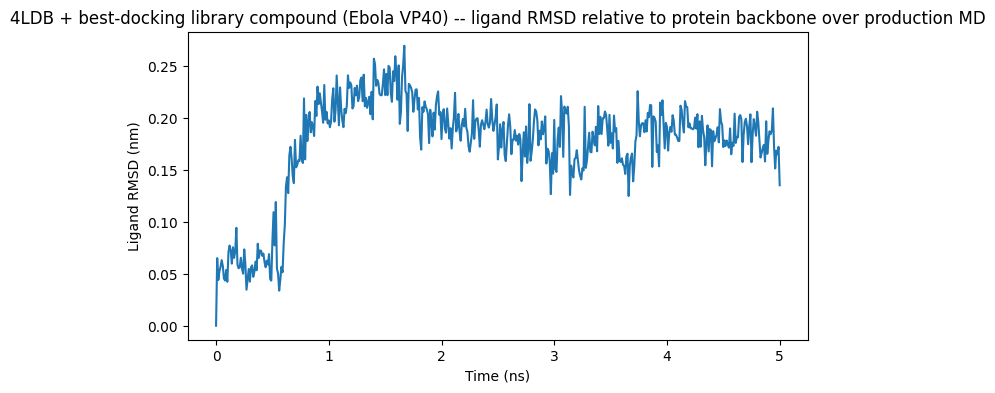

In [25]:
import matplotlib.pyplot as plt

time_ns, rmsd_nm = [], []
with open("results/ligand_rmsd.xvg") as f:
    for line in f:
        if line.startswith(("#", "@")): continue
        t, r = line.split()
        time_ns.append(float(t)); rmsd_nm.append(float(r))

plt.figure(figsize=(8,4))
plt.plot(time_ns, rmsd_nm)
plt.xlabel("Time (ns)"); plt.ylabel("Ligand RMSD (nm)")
plt.title("4LDB + best-docking library compound (Ebola VP40) -- ligand RMSD relative to protein backbone over production MD")
plt.savefig("results/ligand_rmsd_vs_time.png", dpi=150)
plt.show()


## Visualize the docked pose

Two views: (1) an interactive 3D structure -- protein cartoon + the winning compound's top pose
+ the fpocket-detected binding box used for docking -- via `py3Dmol` (a live JS widget: renders
when the notebook is actually run, not in GitHub's static preview). (2) A static bar chart of the
whole library's ranked affinities (`screen_df`), with the winning compound highlighted -- this
is the real screening result, not just the winner's own pose energies, and it renders everywhere
including GitHub.

In [26]:
import sys
!{sys.executable} -m pip install -q py3Dmol

import py3Dmol

# convert the top docked pose (model 1 of the multi-pose PDBQT) to plain PDB for 3Dmol
top_pose_pdb = f"results/docking/{PDB_ID}_{best_cid}_top_pose.pdb"
!obabel {pose_path} -O {top_pose_pdb} -f 1 -l 1

with open(clean_path) as f:
    protein_block = f.read()
with open(top_pose_pdb) as f:
    ligand_block = f.read()

view = py3Dmol.view(width=800, height=500)
view.addModel(protein_block, "pdb")
view.setStyle({"model": 0}, {"cartoon": {"color": "spectrum"}})
view.addModel(ligand_block, "pdb")
view.setStyle({"model": 1}, {"stick": {"colorscheme": "greenCarbon"}})

# fpocket-detected binding box used for docking (Step 3)
view.addBox({
    "center": {"x": float(center[0]), "y": float(center[1]), "z": float(center[2])},
    "dimensions": {"w": float(size[0]), "h": float(size[1]), "d": float(size[2])},
    "color": "yellow", "opacity": 0.2,
})
view.zoomTo({"model": 1})
view.show()


1 molecule converted


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

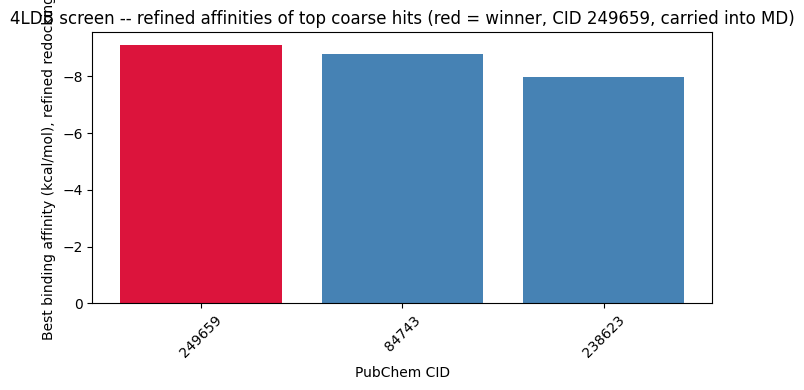

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [27]:
import matplotlib.pyplot as plt

# visualize the refined (Stage 2) screening ranking (screen_df, built in Step 5/6 above) -- only the
# top-N compounds that survived the coarse pass get redocked and shown here, with the overall winner
# (carried into MD) highlighted
ranked = screen_df.sort_values("affinity_kcal_mol")
colors = ["crimson" if cid == best_cid else "steelblue" for cid in ranked["cid"]]

plt.figure(figsize=(7, 4))
plt.bar(range(len(ranked)), ranked["affinity_kcal_mol"], color=colors)
plt.xticks(range(len(ranked)), ranked["cid"], rotation=45)
plt.xlabel("PubChem CID")
plt.ylabel("Best binding affinity (kcal/mol), refined redocking")
plt.title(f"4LDB screen -- refined affinities of top coarse hits (red = winner, CID {best_cid}, carried into MD)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("results/docking/library_screen_barplot.png", dpi=150)
plt.show()
